# 06 — Análise fatorial completo 2³

Este é o caderno inferencial principal, adaptado do exemplo 2ᵏ. A codificação ±1 permite estimar os sete contrastes: A, B, C, AB, AC, BC e ABC. O fator “efeito” é definido como diferença entre médias marginais nos níveis +1 e −1; no desenho 2³, equivale a duas vezes o coeficiente codificado.

**Unidade de análise:** aluno. **Núcleo:** modelo saturado nos dados brutos e testes tipo III robustos HC3. **IC95%:** bootstrap dentro de cada célula. Não usar a ANOVA das réplicas reamostradas como evidência inferencial.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from scipy import stats
from IPython.display import display

configure_plots()

DATA_NAME = "ai_student_impact_dataset.csv"
ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "csv" / DATA_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei csv/{DATA_NAME} em nenhum diretório ancestral "
        f"do diretório atual: {Path.cwd()}"
    )
CSV_PATH = ROOT / "csv" / DATA_NAME
df = pd.read_csv(CSV_PATH)

required = {
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes no CSV: {sorted(missing_columns)}")

df["Delta_GPA"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
PASSIVE_USE_CASES = {"Copywriting/Drafting", "Direct_Answer_Generation"}
df["A"] = np.where(df["Primary_Use_Case"].isin(PASSIVE_USE_CASES), 1, -1)
stem_junior = df.loc[
    (df["Major_Category"] == "STEM") & (df["Year_of_Study"] == "Junior")
].copy()

ANXIETY_Q2 = stem_junior["Anxiety_Level_During_Exams"].median()
STUDY_Q2 = stem_junior["Traditional_Study_Hours"].median()
stem_junior["B"] = np.where(
    stem_junior["Anxiety_Level_During_Exams"] > ANXIETY_Q2, 1, -1
)
stem_junior["C"] = np.where(
    stem_junior["Traditional_Study_Hours"] > STUDY_Q2, 1, -1
)
factorial = stem_junior.copy()

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
CELLS = [
    (a, b, c)
    for c in (-1, 1)
    for b in (-1, 1)
    for a in (-1, 1)
]
cell_number = {cell: number for number, cell in enumerate(CELLS, start=1)}
factorial["celula"] = [
    cell_number[(int(row.A), int(row.B), int(row.C))]
    for row in factorial[["A", "B", "C"]].itertuples(index=False)
]
groups = {
    key: frame["Delta_GPA"].to_numpy()
    for key, frame in factorial.groupby(["A", "B", "C"], sort=False)
}
cell_counts = factorial.groupby(["A", "B", "C"]).size()
if set(groups) != set(CELLS):
    raise ValueError("A classificação não produziu as oito células fatoriais.")
if factorial["Delta_GPA"].isna().any():
    raise ValueError("Há ΔGPA ausente; resolva os dados ausentes antes da análise.")

print(f"Arquivo: {CSV_PATH}")
print(f"Dataset completo: n={len(df):,}")
print(f"Recorte STEM + Junior: n={len(stem_junior):,}")
print(f"Analisados nas oito células: n={len(factorial):,}")
print(f"Cortes: ansiedade Q2={ANXIETY_Q2:g}; estudo Q2={STUDY_Q2:.2f} h")
print(f"Menor célula: n={cell_counts.min():,}")

configure_plots()


Arquivo: /home/wagner/pcc170/entrega2-com_notebooks_adaptados/entrega2-com_notebooks_adaptados/csv/ai_student_impact_dataset.csv
Dataset completo: n=50,000
Recorte STEM + Junior: n=3,279
Analisados nas oito células: n=3,279
Cortes: ansiedade Q2=4; estudo Q2=10.91 h
Menor célula: n=181


## Médias das células e contrastes fatoriais

In [2]:

EFFECTS = {
    "A": lambda k: k[0],
    "B": lambda k: k[1],
    "C": lambda k: k[2],
    "AB": lambda k: k[0] * k[1],
    "AC": lambda k: k[0] * k[2],
    "BC": lambda k: k[1] * k[2],
    "ABC": lambda k: k[0] * k[1] * k[2],
}
cell_means = {cell: groups[cell].mean() for cell in CELLS}
observed_effects = {
    name: sum(sign(cell) * cell_means[cell] for cell in CELLS) / 4
    for name, sign in EFFECTS.items()
}
display(pd.DataFrame({
    "média ΔGPA": pd.Series(cell_means),
    "n": pd.Series({cell: len(groups[cell]) for cell in CELLS}),
}).round(4))
display(pd.Series(observed_effects, name="efeito (ΔGPA)").to_frame().round(4))


,,,média ΔGPA,n
-1,-1,-1,0.1963,667
1,-1,-1,0.1520,210
-1,1,-1,0.2005,576
1,1,-1,0.0915,187
-1,-1,1,0.3170,639
1,-1,1,0.2523,235
-1,1,1,0.3231,584
1,1,1,0.2325,181


,efeito (ΔGPA)
A,-0.0772
B,-0.0175
C,0.1211
AB,-0.0226
AC,-0.0005
BC,0.0107
ABC,0.0097


## Modelo principal e testes robustos

ANOVA tipo III no modelo saturado, com erros HC3. Em um desenho desbalanceado, os erros-padrão clássicos não são apropriados diante da heterocedasticidade observada.

In [3]:

import statsmodels.api as sm
import statsmodels.formula.api as smf

fit_raw = smf.ols("Delta_GPA ~ A * B * C", data=factorial).fit()
fit_hc3 = smf.ols("Delta_GPA ~ A * B * C", data=factorial).fit(cov_type="HC3")
anova_hc3 = sm.stats.anova_lm(fit_hc3, typ=3, robust="hc3")
anova_hc3 = anova_hc3.drop(index=["Intercept", "Residual"], errors="ignore")
anova_hc3.index = anova_hc3.index.str.replace(":", "", regex=False)
p_hc3 = anova_hc3["PR(>F)"].reindex(EFFECTS)
coefficient_effects = {
    term.replace(":", ""): 2 * fit_raw.params[term]
    for term in fit_raw.params.index
    if term != "Intercept"
}
core_table = pd.DataFrame({
    "efeito_por_contraste": pd.Series(observed_effects),
    "2 × coeficiente": pd.Series(coefficient_effects),
    "p_HC3_tipo_III": p_hc3,
})
display(core_table.round(5))
print(f"n={len(factorial):,}; R²={fit_raw.rsquared:.3f}")
print(f"Levene/Brown–Forsythe p={stats.levene(*[groups[c] for c in CELLS], center='median').pvalue:.3g}")


,efeito_por_contraste,2 × coeficiente,p_HC3_tipo_III
A,-0.07716,-0.07716,0.00000
AB,-0.02264,-0.02264,0.00414
ABC,0.00973,0.00973,0.21782
AC,-0.00049,-0.00049,0.95072
B,-0.01749,-0.01749,0.02676
BC,0.01067,0.01067,0.17656
C,0.12114,0.12114,0.00000


n=3,279; R²=0.129
Levene/Brown–Forsythe p=2.65e-05


## Bootstrap estratificado para IC95%

,efeito,IC95% inferior,IC95% superior,p_HC3_tipo_III,IC exclui zero
A,-0.0772,-0.0920,-0.0621,0.0000,True
B,-0.0175,-0.0329,-0.0019,0.0268,True
C,0.1211,0.1058,0.1364,0.0000,True
AB,-0.0226,-0.0384,-0.0074,0.0041,True
AC,-0.0005,-0.0156,0.0148,0.9507,False
BC,0.0107,-0.0051,0.0263,0.1766,False
ABC,0.0097,-0.0063,0.0253,0.2178,False


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figura salva: 06_forest_plot_efeitos.png (PNG) e 06_forest_plot_efeitos.pdf (PDF)


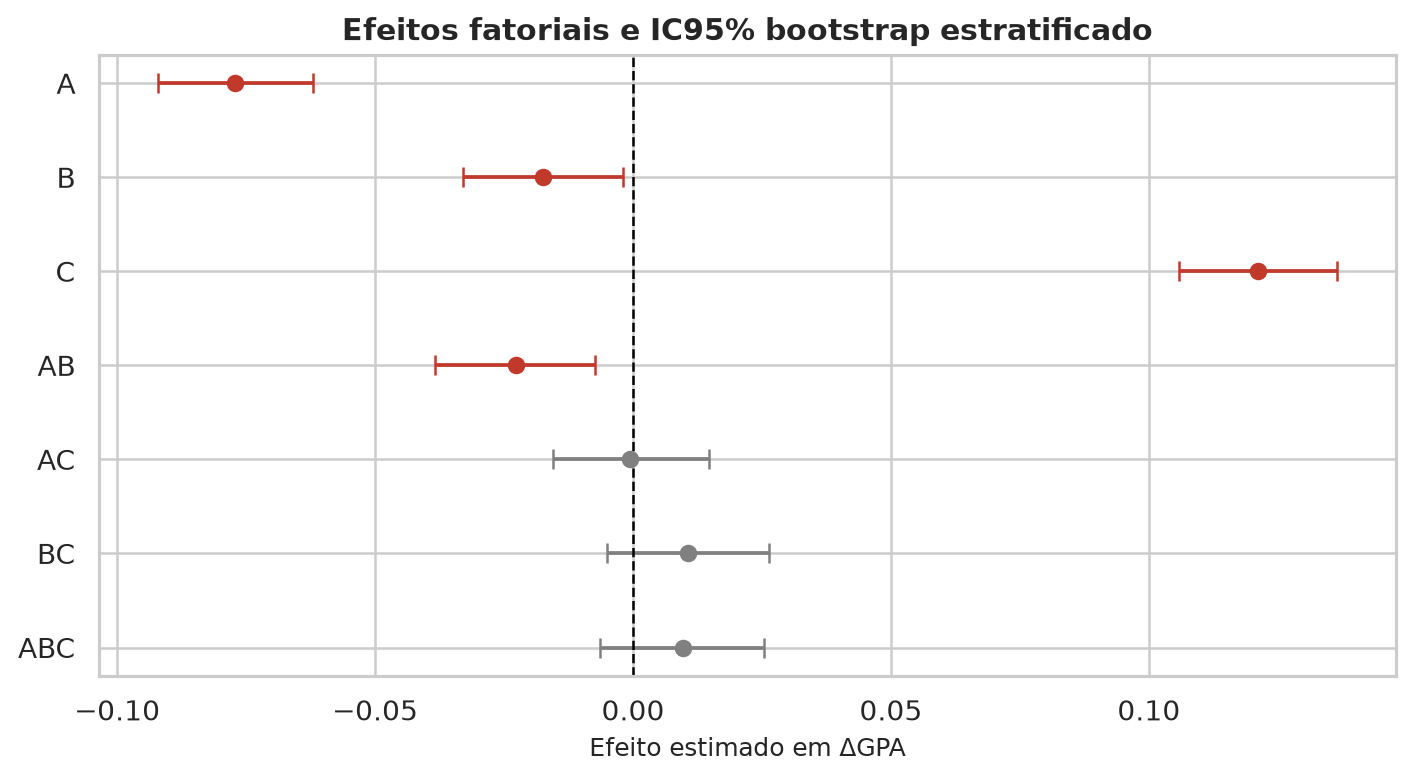

In [4]:

N_BOOT = 5000
SEED = 42
rng = np.random.default_rng(SEED)
bootstrap_effects = np.empty((N_BOOT, len(EFFECTS)))
effect_names = list(EFFECTS)
for b in range(N_BOOT):
    means_b = {
        cell: groups[cell][
            rng.integers(0, len(groups[cell]), len(groups[cell]))
        ].mean()
        for cell in sorted(CELLS)
    }
    bootstrap_effects[b] = [
        sum(sign(cell) * means_b[cell] for cell in CELLS) / 4
        for sign in EFFECTS.values()
    ]

bootstrap = pd.DataFrame(bootstrap_effects, columns=effect_names)
ci_table = pd.DataFrame({
    "efeito": pd.Series(observed_effects),
    "IC95% inferior": bootstrap.quantile(0.025),
    "IC95% superior": bootstrap.quantile(0.975),
    "p_HC3_tipo_III": p_hc3,
})
ci_table["IC exclui zero"] = (
    (ci_table["IC95% inferior"] > 0)
    | (ci_table["IC95% superior"] < 0)
)
display(ci_table.round(4))

ordered = ci_table.loc[effect_names].iloc[::-1]
colors = ["#c0392b" if excludes else "gray" for excludes in ordered["IC exclui zero"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
for position, ((term, row), color) in enumerate(zip(ordered.iterrows(), colors)):
    ax.errorbar(
        row["efeito"], position,
        xerr=[[
            row["efeito"] - row["IC95% inferior"],
        ], [
            row["IC95% superior"] - row["efeito"],
        ]],
        fmt="o", color=color, capsize=4,
    )
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(ordered)), ordered.index)
ax.set_xlabel("Efeito estimado em ΔGPA")
ax.set_title("Efeitos fatoriais e IC95% bootstrap estratificado")
plt.tight_layout()
save_figure(fig, "06_forest_plot_efeitos")


## Gráficos dos efeitos principais e das interações

As médias são calculadas dando o mesmo peso às células, coerentemente com os contrastes codificados ±1. São visualizações dos contrastes estimados, não médias marginais ponderadas pelo n observado.

Figura salva: 06_efeitos_principais.png (PNG) e 06_efeitos_principais.pdf (PDF)


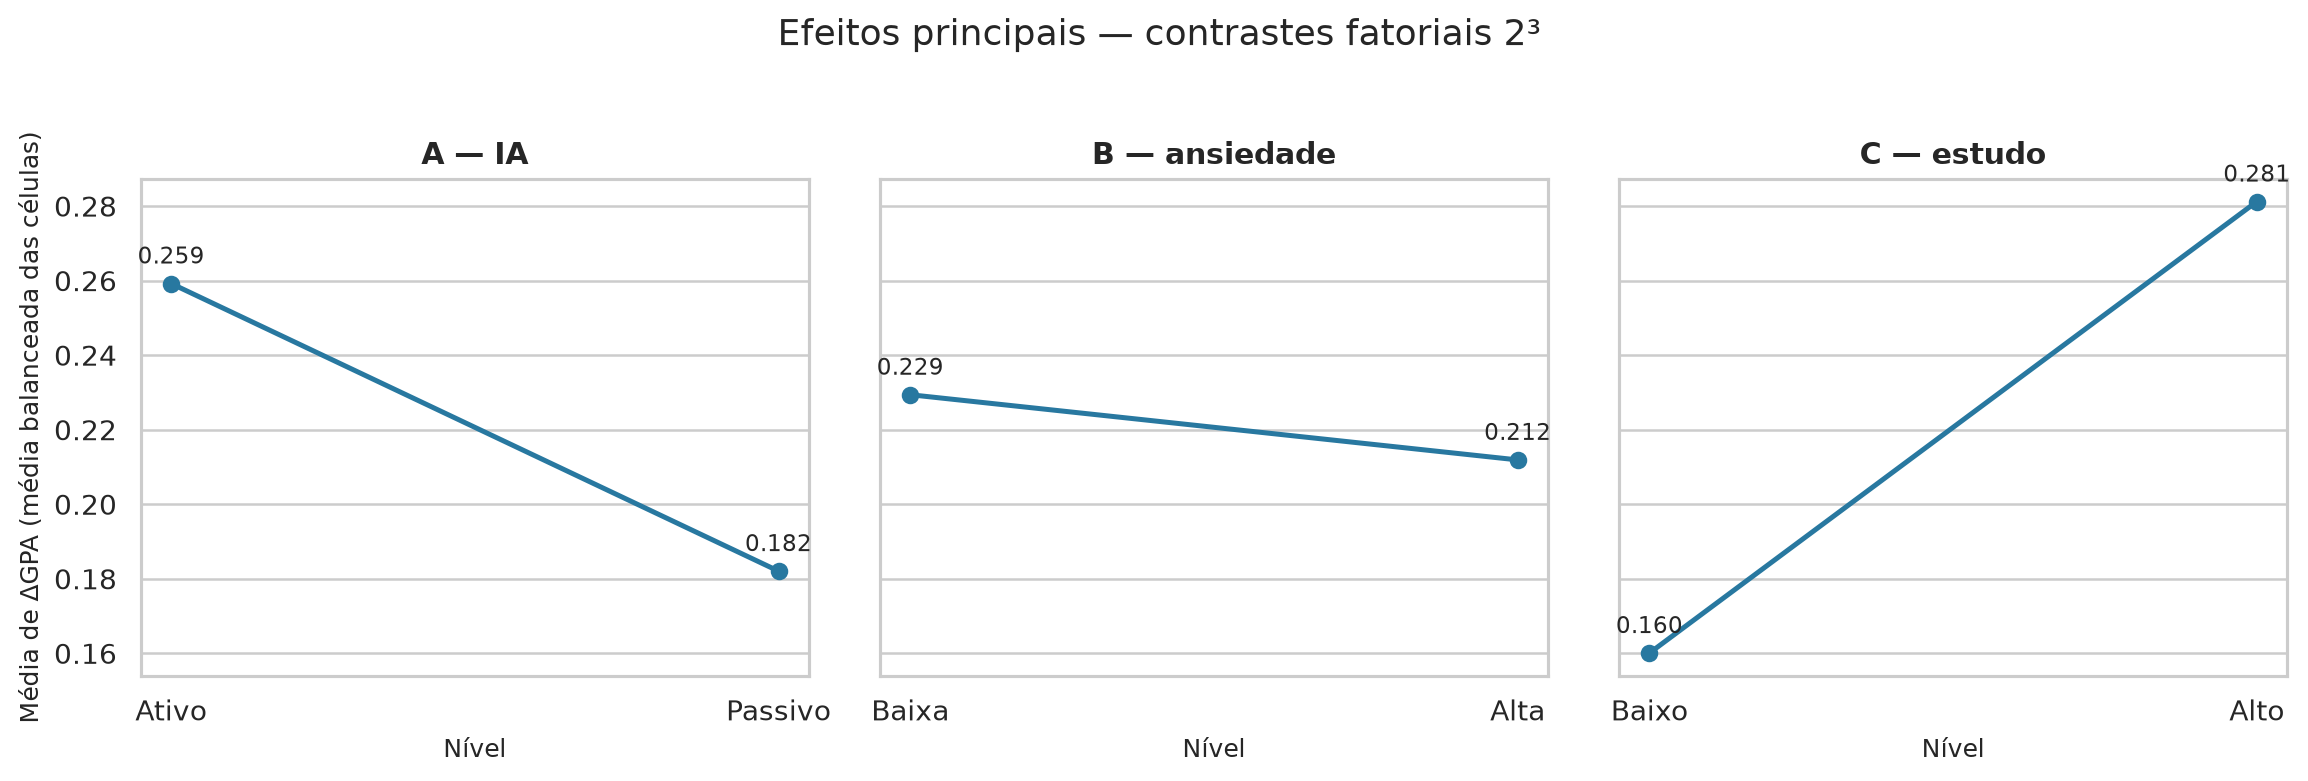

Figura salva: 06_efeito_principal_A.png (PNG) e 06_efeito_principal_A.pdf (PDF)


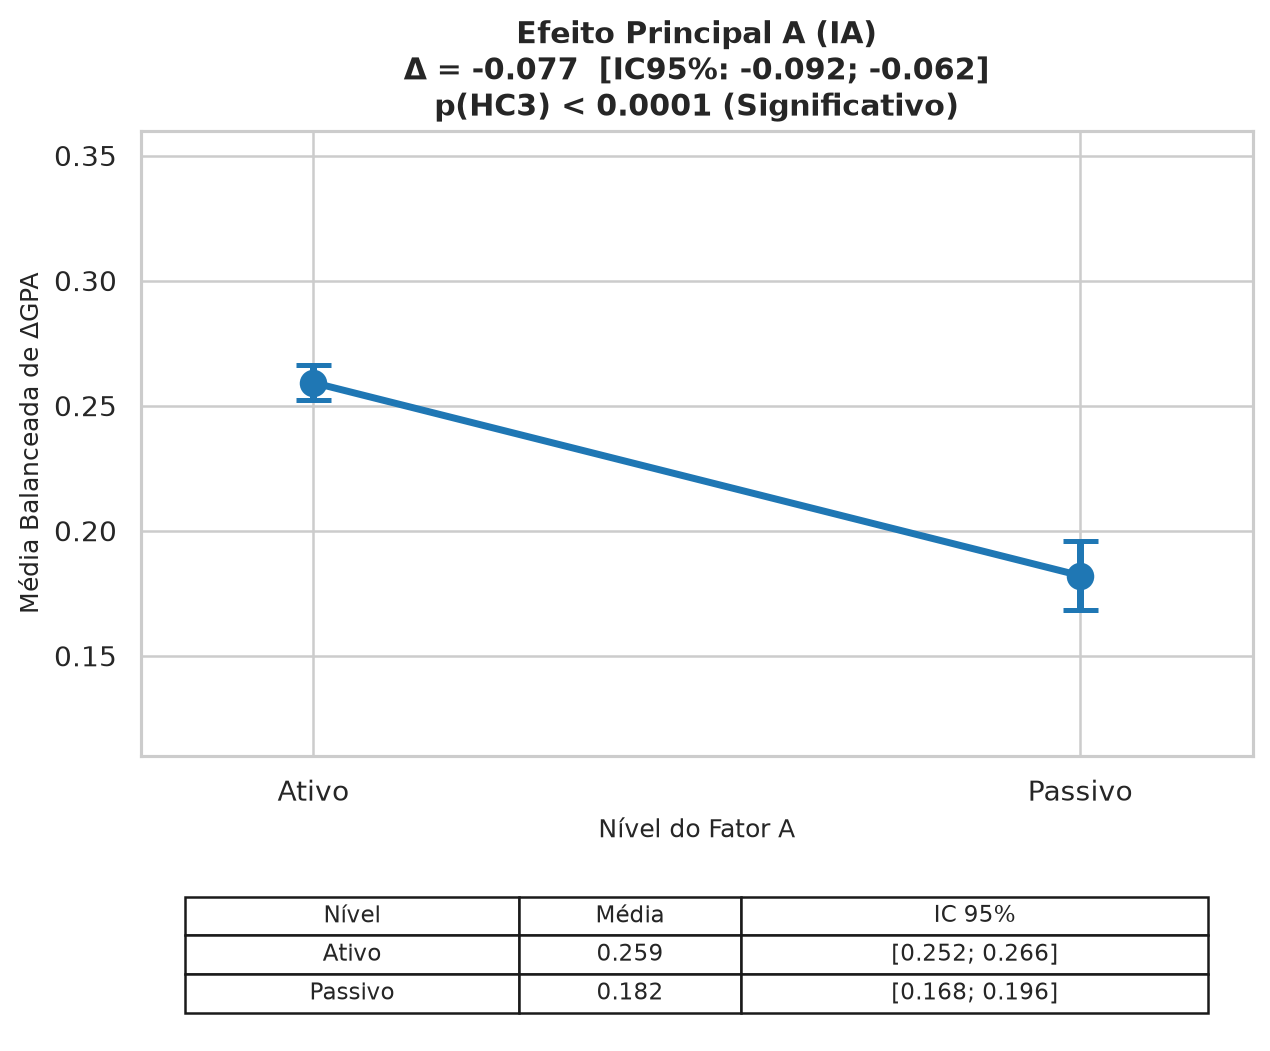

Figura salva: 06_efeito_principal_B.png (PNG) e 06_efeito_principal_B.pdf (PDF)


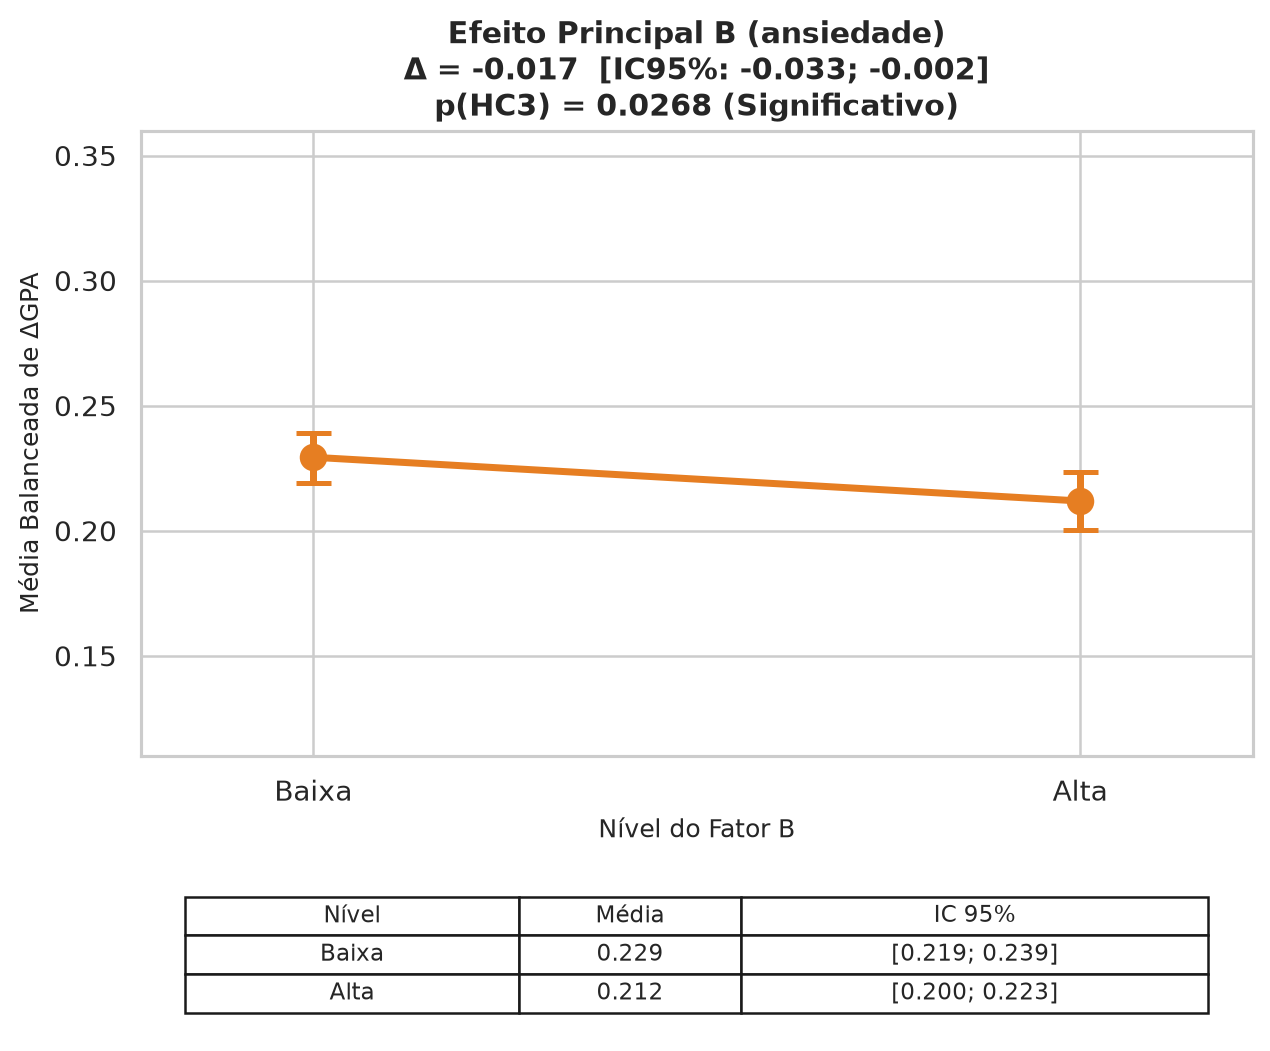

Figura salva: 06_efeito_principal_C.png (PNG) e 06_efeito_principal_C.pdf (PDF)


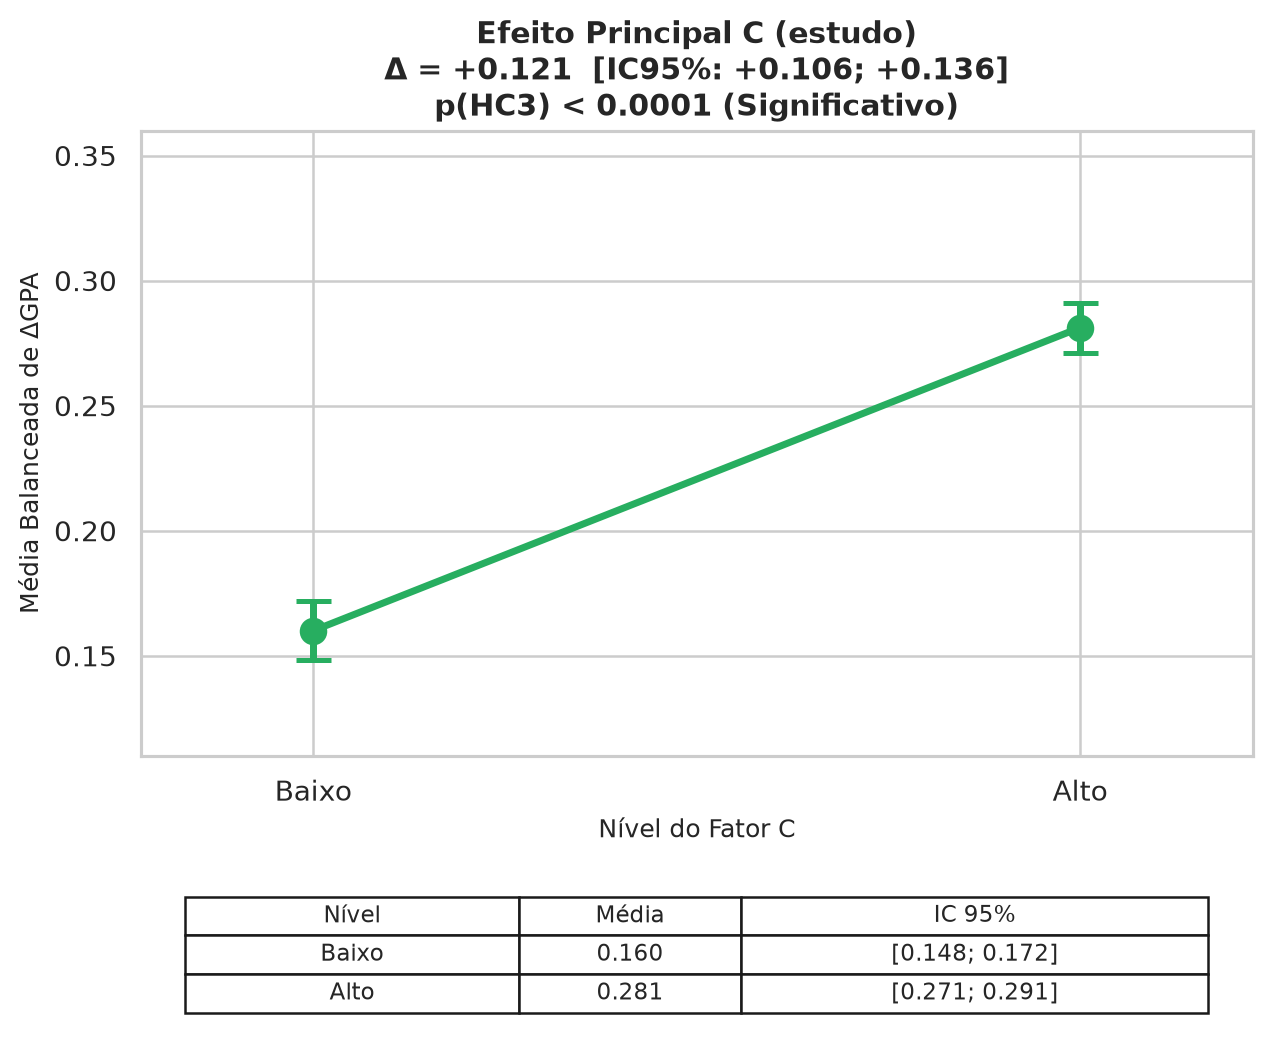

Figura salva: 06_interacoes_fatoriais.png (PNG) e 06_interacoes_fatoriais.pdf (PDF)


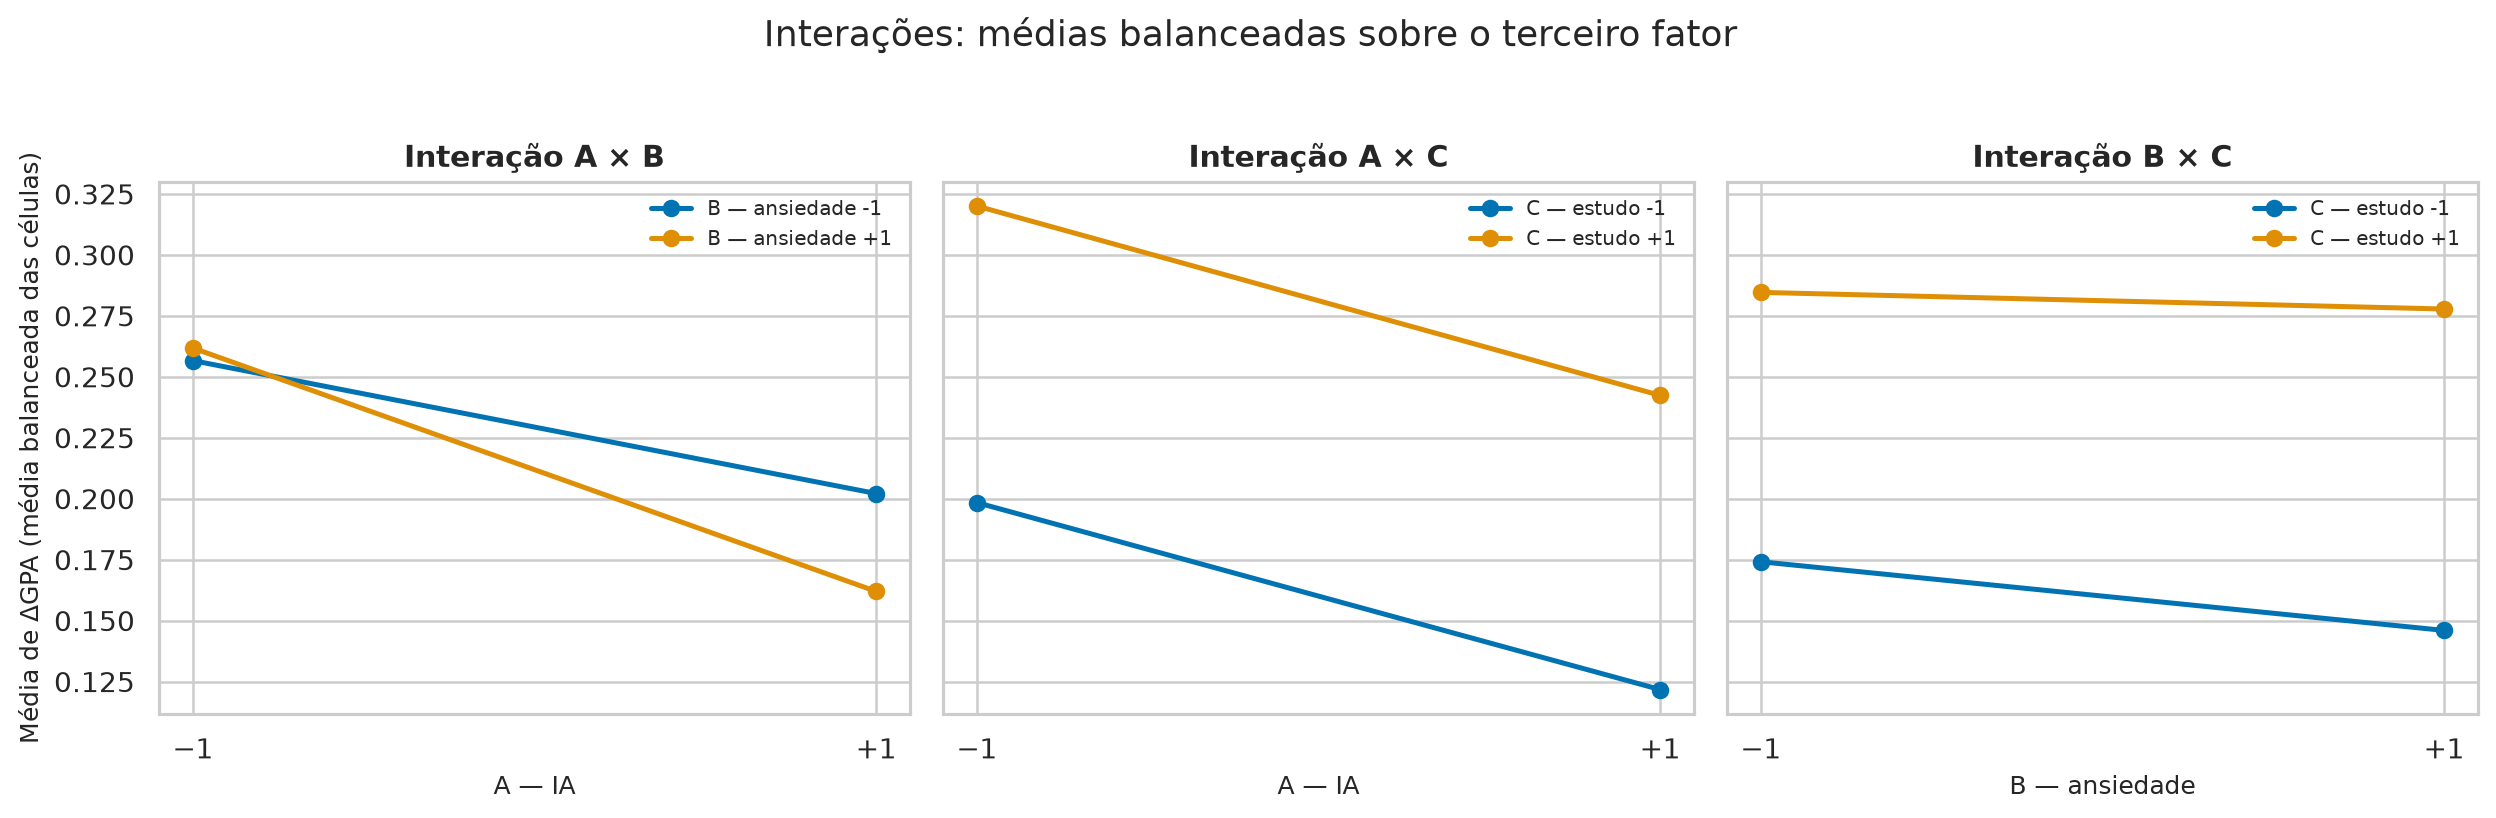

Figura salva: 06_pareto_hc3.png (PNG) e 06_pareto_hc3.pdf (PDF)


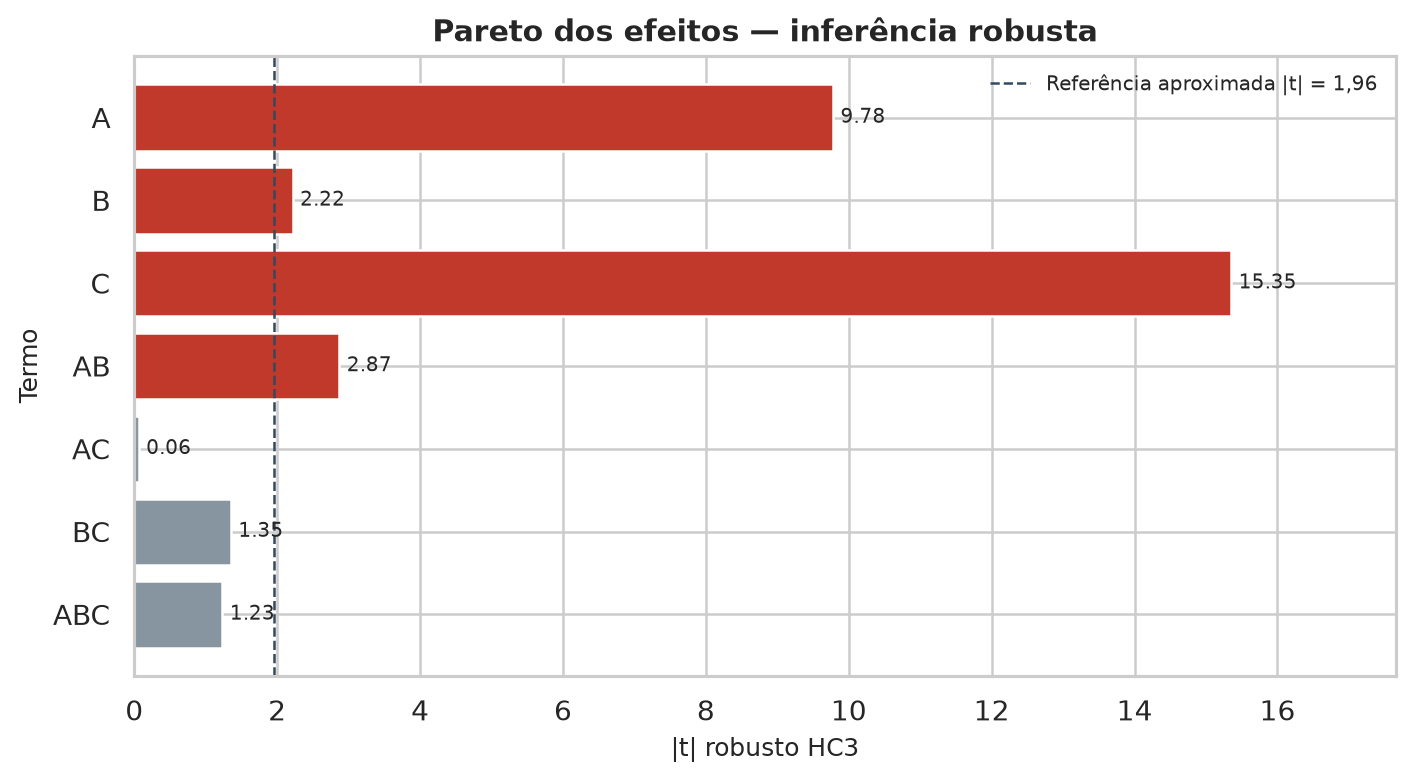

In [5]:
def equal_cell_mean(fixed_levels):
    selected = [
        cell_means[cell]
        for cell in CELLS
        if all(cell[index] == level for index, level in fixed_levels.items())
    ]
    return float(np.mean(selected))

factor_info = [
    (0, "A — IA", {-1: "Ativo", 1: "Passivo"}),
    (1, "B — ansiedade", {-1: "Baixa", 1: "Alta"}),
    (2, "C — estudo", {-1: "Baixo", 1: "Alto"}),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (index, label, level_names) in zip(axes, factor_info):
    marginal_means = [equal_cell_mean({index: level}) for level in (-1, 1)]
    ax.plot([-1, 1], marginal_means, marker="o", linewidth=2, color="#2878a0")
    for level, mean in zip((-1, 1), marginal_means):
        ax.annotate(f"{mean:.3f}", (level, mean), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks([-1, 1], [level_names[-1], level_names[1]])
    ax.set(title=label, xlabel="Nível")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Média de ΔGPA (média balanceada das células)")
fig.suptitle("Efeitos principais — contrastes fatoriais 2³", y=1.03)
save_figure(fig, "06_efeitos_principais")

# Exportar gráficos individuais de efeitos principais com IC95% (bootstrap)
colors_map = {"A": "#1f77b4", "B": "#e67e22", "C": "#27ae60"}
for index, label, level_names in factor_info:
    term = label.split(" ")[0]
    m_neg = equal_cell_mean({index: -1})
    m_pos = equal_cell_mean({index: 1})
    ef = observed_effects[term]
    ic_inf = ci_table.loc[term, "IC95% inferior"]
    ic_sup = ci_table.loc[term, "IC95% superior"]
    p_val = p_hc3[term]
    p_str = "< 0.0001" if p_val < 0.0001 else f"= {p_val:.4f}"
    
    # Bootstrap para IC das médias marginais
    b_negs = [np.mean([groups[c][rng.integers(0, len(groups[c]), len(groups[c]))].mean() for c in CELLS if c[index] == -1]) for _ in range(2000)]
    b_poss = [np.mean([groups[c][rng.integers(0, len(groups[c]), len(groups[c]))].mean() for c in CELLS if c[index] == 1]) for _ in range(2000)]
    ci_m_neg = np.quantile(b_negs, [0.025, 0.975])
    ci_m_pos = np.quantile(b_poss, [0.025, 0.975])
    
    yerr = [[m_neg - ci_m_neg[0], m_pos - ci_m_pos[0]], [ci_m_neg[1] - m_neg, ci_m_pos[1] - m_pos]]
    
    fig_ind, (ax_ind, ax_summary) = plt.subplots(
        2, 1, figsize=(7.2, 6.0), gridspec_kw={"height_ratios": [4.8, 1.2]}
    )
    ax_ind.errorbar([-1, 1], [m_neg, m_pos], yerr=yerr, fmt="-o", markersize=10, linewidth=2.8,
                    capsize=7, capthick=2, color=colors_map[term], ecolor=colors_map[term])
    ax_ind.set_xticks([-1, 1], [level_names[-1], level_names[1]])
    ax_ind.set_xlim(-1.45, 1.45)
    ax_ind.set_ylim(
        min(0.12, ci_m_neg[0], ci_m_pos[0]) - 0.01,
        max(0.35, ci_m_neg[1], ci_m_pos[1]) + 0.01,
    )
    ax_summary.axis("off")
    summary = ax_summary.table(
        cellText=[
            [level_names[-1], f"{m_neg:.3f}", f"[{ci_m_neg[0]:.3f}; {ci_m_neg[1]:.3f}]"],
            [level_names[1], f"{m_pos:.3f}", f"[{ci_m_pos[0]:.3f}; {ci_m_pos[1]:.3f}]"],
        ],
        colLabels=["Nível", "Média", "IC 95%"],
        cellLoc="center",
        colLoc="center",
        colWidths=[0.30, 0.20, 0.42],
        loc="center",
    )
    summary.auto_set_font_size(False)
    summary.set_fontsize(9)
    summary.scale(1, 1.25)
    sign_str = "+" if ef > 0 else ""
    ax_ind.set(
        title=(f"Efeito Principal {term} ({label.split('— ')[-1]})\n"
               f"Δ = {sign_str}{ef:.3f}  [IC95%: {ic_inf:+.3f}; {ic_sup:+.3f}]\n"
               f"p(HC3) {p_str} (Significativo)"),
        xlabel=f"Nível do Fator {term}",
        ylabel="Média Balanceada de ΔGPA",
    )
    save_figure(fig_ind, f"06_efeito_principal_{term}")


interaction_specs = [
    (0, 1, 2, "Interação A × B", "A — IA", "B — ansiedade"),
    (0, 2, 1, "Interação A × C", "A — IA", "C — estudo"),
    (1, 2, 0, "Interação B × C", "B — ansiedade", "C — estudo"),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, (first, second, omitted, title, x_label, line_label) in zip(axes, interaction_specs):
    for second_level in (-1, 1):
        values = [
            equal_cell_mean({first: first_level, second: second_level})
            for first_level in (-1, 1)
        ]
        ax.plot(
            [-1, 1], values, marker="o", linewidth=2,
            label=f"{line_label} {second_level:+d}",
        )
    ax.set(
        title=title,
        xlabel=x_label,
        xticks=[-1, 1],
        xticklabels=["−1", "+1"],
    )
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Média de ΔGPA (média balanceada das células)")
fig.suptitle("Interações: médias balanceadas sobre o terceiro fator", y=1.03)
save_figure(fig, "06_interacoes_fatoriais")

term_order = ["A", "B", "C", "AB", "AC", "BC", "ABC"]
hc3_t = pd.Series({
    term.replace(":", ""): abs(float(fit_hc3.tvalues[term]))
    for term in fit_hc3.tvalues.index
    if term != "Intercept"
}).reindex(term_order)
hc3_p = p_hc3.reindex(term_order)
bar_colors = ["#c0392b" if p < 0.05 else "#8795a1" for p in hc3_p]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(term_order[::-1], hc3_t.reindex(term_order[::-1]), color=bar_colors[::-1])
ax.axvline(1.96, color="#34495e", linestyle="--", linewidth=1,
           label="Referência aproximada |t| = 1,96")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set(xlabel="|t| robusto HC3", ylabel="Termo", title="Pareto dos efeitos — inferência robusta")
ax.legend(frameon=False, fontsize=8)
ax.margins(x=0.15)
save_figure(fig, "06_pareto_hc3")


## Interpretação

Leia os sinais junto aos níveis codificados: efeito negativo em A indica menor ΔGPA no grupo de uso passivo; efeito positivo em C indica maior ΔGPA no grupo com estudo acima da mediana. Avalie magnitude, intervalo e p robusto em conjunto. AC, BC e ABC não devem ser tratados como evidência de interação quando seus ICs incluem zero. Significância estatística não implica importância prática.

O R² e a tabela tipo III respondem a resumos diferentes, especialmente no desenho desbalanceado; não interpretar os percentuais tipo III como parcelas independentes da variância. Os resultados são observacionais e dependem da dicotomização de B e C. Relatar também a regressão contínua e a regra alternativa de quartis como sensibilidades.